# 03 — DWR and cloud mask

Much shorter than the real-data version. Removed, with reasons:

- **`avg_ze_time`** — the Time axis is cloud thickness. Averaging along it would
  mix different cloud scenes together.
- **despiking** — no measurement noise to spike.
- **sensitivity-limit masks and margin sweeps** — PAMTRA has no noise floor.
- **drizzle mask** — liquid cloud only, no drizzle in this simulation.
- **neighbour / box filter** — exists to reject isolated noise gates.

What remains: form DWR, mask to cloudy gates, save.

In [36]:
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/processed/pamtra_test_1")
ds    = xr.open_dataset(DATA_DIR / "pamtra_aligned.nc")
coeff = xr.open_dataset(DATA_DIR / "coefficients.nc")

In [37]:
#ds.close()
#coeff.close()

## DWR

In [38]:
dwr = ds["Ze_Ka_true"] - ds["Ze_W_true"]
dwr.name = "DWR"
dwr.attrs["units"] = "dB"

print(f"DWR range: {float(dwr.min()):.2f} to {float(dwr.max()):.2f} dB")

DWR range: 0.65 to 6.27 dB


## Cloud mask

With no noise floor the mask is simply where both frequencies return a finite
value. `LWC_true > 0` is kept as a cross-check — the two should agree closely,
and any disagreement is worth understanding before running the retrieval.

In [39]:
cloud_mask = ds["Ze_Ka"].notnull() & ds["Ze_W"].notnull() & dwr.notnull()
cloud_mask.name = "cloud_mask"

truth_mask = ds["LWC_true"] > 0

print(f"gates from finite Ze : {int(cloud_mask.sum())}")
print(f"gates from LWC > 0   : {int(truth_mask.sum())}")
print(f"in Ze mask but no LWC: {int((cloud_mask & ~truth_mask).sum())}")
print(f"has LWC but no Ze    : {int((truth_mask & ~cloud_mask).sum())}")

gates_per_scene = cloud_mask.sum("range")
print(f"\ncloud gates per scene: min {int(gates_per_scene.min())}, "
      f"median {int(gates_per_scene.median())}, max {int(gates_per_scene.max())}")
print("scenes with < 3 gates (skipped by retrieval):",
      int((gates_per_scene < 3).sum()))

gates from finite Ze : 1485
gates from LWC > 0   : 1485
in Ze mask but no LWC: 0
has LWC but no Ze    : 0

cloud gates per scene: min 1, median 27, max 54
scenes with < 3 gates (skipped by retrieval): 2


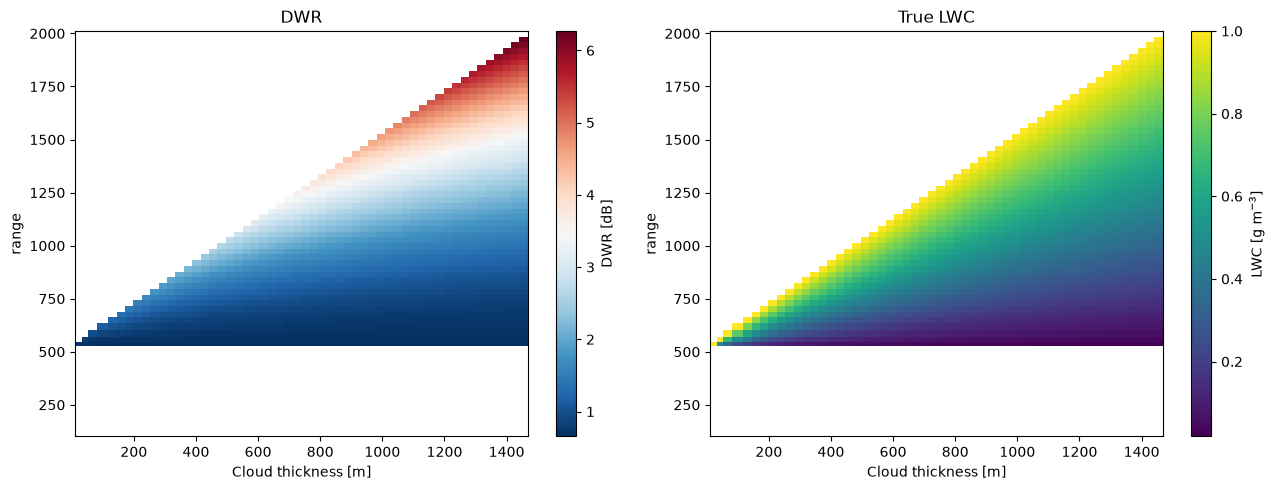

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

dwr.where(cloud_mask).plot(x="Time", y="range", cmap="RdBu_r", ax=axes[0],
                           cbar_kwargs={"label": "DWR [dB]"})
axes[0].set_title("DWR"); axes[0].set_xlabel("Cloud thickness [m]")

ds["LWC_true"].where(truth_mask).plot(x="Time", y="range", cmap="viridis", ax=axes[1],
                                      cbar_kwargs={"label": "LWC [g m$^{-3}$]"})
axes[1].set_title("True LWC"); axes[1].set_xlabel("Cloud thickness [m]")

plt.tight_layout(); plt.show()

## Save retrieval input

In [43]:
ds_retrieval = xr.Dataset({
    "Ze_W": ds["Ze_W"],
    "Ze_Ka": ds["Ze_Ka"],
    "T_cloud": ds["T_cloud"],
    "DWR": dwr,
    "cloud_mask": cloud_mask,
    "common_mask": cloud_mask.rename("common_mask"),
    "alpha_W": coeff["alpha_W"],
    "alpha_Ka": coeff["alpha_Ka"],
    "kappa_W": coeff["kappa_W"],
    "kappa_Ka": coeff["kappa_Ka"],
    "LWC_true": ds["LWC_true"],
}, attrs={
    "description": "PAMTRA synthetic inputs for the Zhu (2019) LWC retrieval",
    "note": "Time dimension is cloud thickness. Do not average along it.",
    "created_by": "03_dwr_and_masking.ipynb",
})
ds_retrieval = ds_retrieval.assign_coords(cloud_thickness=ds["cloud_thickness"])

ds_retrieval.to_netcdf(DATA_DIR / "retrieval_input.nc")
print("Saved -> retrieval_input.nc")
print(ds_retrieval)

Saved -> retrieval_input.nc
<xarray.Dataset> Size: 297kB
Dimensions:          (range: 74, Time: 54)
Coordinates:
  * range            (range) float64 592B 111.8 134.2 ... 1.971e+03 1.998e+03
  * Time             (Time) float64 432B 22.36 44.72 ... 1.427e+03 1.454e+03
    cloud_thickness  (Time) float64 432B ...
Data variables:
    Ze_W             (Time, range) float64 32kB nan nan nan ... -33.04 nan
    Ze_Ka            (Time, range) float64 32kB nan nan nan ... -21.3 -21.34 nan
    T_cloud          (Time, range) float64 32kB ...
    DWR              (Time, range) float64 32kB nan nan nan ... 6.076 6.268 nan
    cloud_mask       (Time, range) bool 4kB False False False ... True False
    common_mask      (Time, range) bool 4kB False False False ... True False
    alpha_W          (Time, range) float64 32kB ...
    alpha_Ka         (Time, range) float64 32kB ...
    kappa_W          (Time, range) float64 32kB ...
    kappa_Ka         (Time, range) float64 32kB ...
    LWC_true         